In [1]:
import matplotlib.pyplot as plt

import numpy as np

import scipy.stats as st
from scipy.integrate import solve_ivp
from scipy.interpolate import CubicSpline

## Modelo SIR

El modelo SIR es uno de los modelos epidemiológicos más simples capaces de capturar características típicas de los brotes epidémicos. El nombre del modelo proviene de las iniciales:

- Población susceptible (S), individuos sin inmunidad al agente infeccioso, y que por tanto puede ser infectada si es expuesta al agente infeccioso.
- Población infectada (I), individuos que están infectados en un momento dado y pueden transmitir la infección a individuos de la población susceptible con la que entran en contacto.
- Población recuperada y fallecidos (R), individuos que son inmunes a la infección (o fallecidos), y consecuentemente no afectan a la transmisión cuando entran en contacto con otros individuos.

El modelo relaciona las variaciones de las tres poblaciones a través de la tasa de infección y el período infeccioso promedio. Suponiendo una población total constante: $N = S + I + R$, el modelo SIR viene dado por las siguientes ecuaciones diferenciales:



## Datos

In [2]:
data = [1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4]
t = np.arange(len(data))
n_poblacion = 763

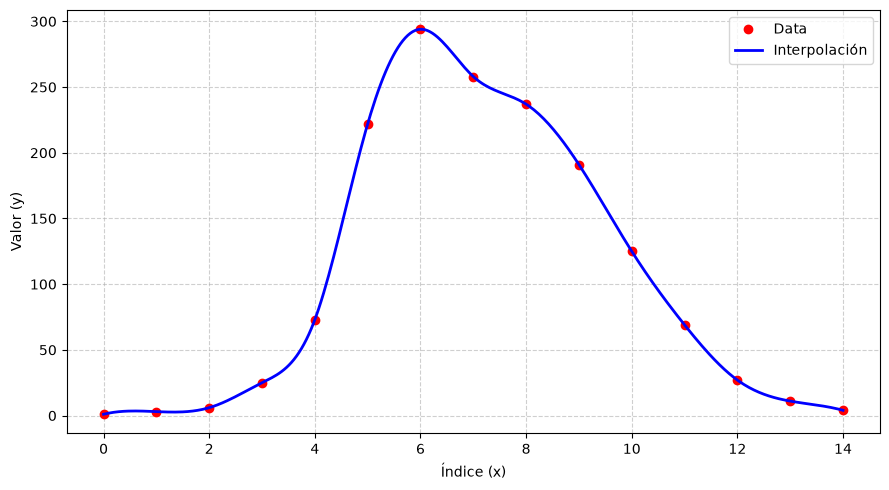

In [ ]:
cs = CubicSpline(t, data)

# Generación de puntos densos para graficar la curva suave
t_denso = np.linspace(0,14, 300)
y_spline = cs(t_denso)

# Graficar
plt.figure(figsize=(9, 5))
plt.plot(t, data, "ro", label="Data", markersize=6)
plt.plot(t_denso, y_spline, "b-", label="Interpolación", linewidth=2)

# plt.title("Interpolación por Splines Cúbicos")
plt.xlabel("Índice (x)")
plt.ylabel("Valor (y)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## Solucion númerica libre

In [4]:
def sir_sist(t, y, N, beta, gamma):
    S, I, R = y
    dSdt = -beta * S * I
    dIdt = beta * S * I - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]

In [5]:
def sol_sir_sist(I0, R0, t_span, t_eval, N, beta, gamma):
    y0 = [N - I0 - R0, I0, R0]

    args = (N, beta, gamma)

    sol = solve_ivp(
        fun = sir_sist,
        t_span = t_span,
        t_eval = t_eval,
        y0 = y0,
        args = args
    )
    return sol

I0, R0 = 1, 0

t_span = (0, 14)
t_eval = np.linspace(0,14,14 + 1)

beta = 0.01
gamma = 0.5

solution = sol_sir_sist(I0, R0, t_span, t_eval, n_poblacion, beta, gamma)

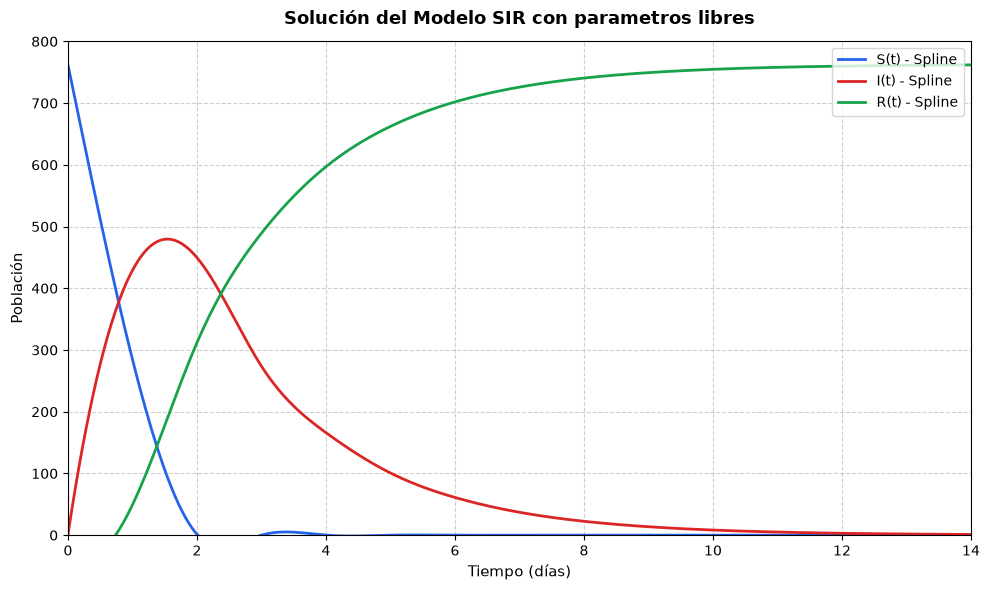

In [6]:
# 1. Puntos temporales donde solve_ivp evaluó la solución
S_pts, I_pts, R_pts = solution.y


# 2. Ajuste de splines cúbicos para cada compartimento
cs_S = CubicSpline(t_eval, S_pts)
cs_I = CubicSpline(t_eval, I_pts)
cs_R = CubicSpline(t_eval, R_pts)


# 3. Malla fina de tiempo para evaluar la interpolación suave
t_fine = np.linspace(t_span[0], t_span[1], 500)
S_spline = cs_S(t_fine)
I_spline = cs_I(t_fine)
R_spline = cs_R(t_fine)

# 4. Graficación
plt.figure(figsize=(10, 6), dpi=100)

# Curvas continuas obtenidas con la interpolación por splines
plt.plot(t_fine, S_spline, label="S(t) - Spline", color="#2563eb", lw=2)
plt.plot(t_fine, I_spline, label="I(t) - Spline", color="#dc2626", lw=2)
plt.plot(t_fine, R_spline, label="R(t) - Spline", color="#16a34a", lw=2)

# Personalización del gráfico
plt.title("Solución del Modelo SIR con parametros libres", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Tiempo (días)", fontsize=11)
plt.ylabel("Población", fontsize=11)
plt.xlim(t_span[0], t_span[1])
plt.ylim(0, n_poblacion * 1.05)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(frameon=True, fontsize=10, loc="upper right")
plt.tight_layout()
plt.show()


## Ajuste por minimos cuadrados usando MCMC

In [7]:
def log_like(theta):
    beta, gamma, sigma = theta

    if (beta <= 0 or beta >= 1) or (gamma <= 0 or gamma >= 1) or (sigma <= 0):
        return -np.inf

    y = np.array(data)

    solution = sol_sir_sist(I0, R0, t_span, t_eval, n_poblacion, beta, gamma)
    if not solution.success:
        return -np.inf

    y_est = solution.y[1]

    n_data = len(data)

    delta2 = np.pow((y - y_est),2)
    loglike = -n_data * np.log(sigma) - np.sum(delta2)/(2*np.pow(sigma,2))

    return loglike

def log_prior(theta):
    beta, gamma, sigma = theta

    if (beta > 0 and beta < 1) and (gamma > 0 and gamma < 1) and (sigma > 0):
        return 0
    else:
        return -np.inf

def log_posterior(theta):
    beta, gamma, sigma = theta
    prior = log_prior(theta)

    if not np.isfinite(prior):
        return -np.inf
    else:
        return log_like(theta) + prior


In [8]:
from tqdm import tqdm

def metropolis_hastings_sampling(n_iter, theta_0, step_size):
    n_params = len(theta_0)
    #n_data = len(data)

    chain = np.zeros((n_iter, n_params))
    chain[0] = theta_0

    theta_actual = theta_0
    log_post_actual = log_posterior(theta_actual)
    n_accepted = 0

    for i in tqdm(range(1, n_iter)):
        theta_proposed = theta_actual + step_size * np.random.normal(0, 1, n_params)

        log_post_propossed = log_posterior(theta_proposed)

        log_ratio = log_post_propossed - log_post_actual

        u = np.random.uniform(0,1)
        if np.log(u) < log_ratio:
            theta_actual = theta_proposed
            log_post_actual = log_post_propossed
            n_accepted += 1

        chain[i] = theta_actual

    print(f"Tasa de aceptación: {n_accepted / (n_iter - 1):.2%}")
    return chain


In [15]:
iter = 10000
n_chains = 4

theta_0 = [[0.005, 0.5, 18], [0.002, 0.5, 21], [0.005, 0.2, 20], [0.002, 0.2, 19]]
steps = [0.0001, 0.005, 1.1]
#steps = [[0.0001, 0.005, 0.001], [0.0001, 0.005, 0.001], [0.0001, 0.005, 0.01], [0.0001, 0.005, 0.01]]

chains = []

for i in range(n_chains):
    chains.append(metropolis_hastings_sampling(iter, theta_0[i], steps))

  0%|          | 0/9999 [00:00<?, ?it/s]

100%|██████████| 9999/9999 [01:08<00:00, 145.10it/s]


Tasa de aceptación: 37.97%


100%|██████████| 9999/9999 [00:40<00:00, 245.78it/s]


Tasa de aceptación: 34.30%


100%|██████████| 9999/9999 [00:53<00:00, 187.92it/s]


Tasa de aceptación: 36.25%


100%|██████████| 9999/9999 [01:05<00:00, 153.69it/s]

Tasa de aceptación: 35.03%


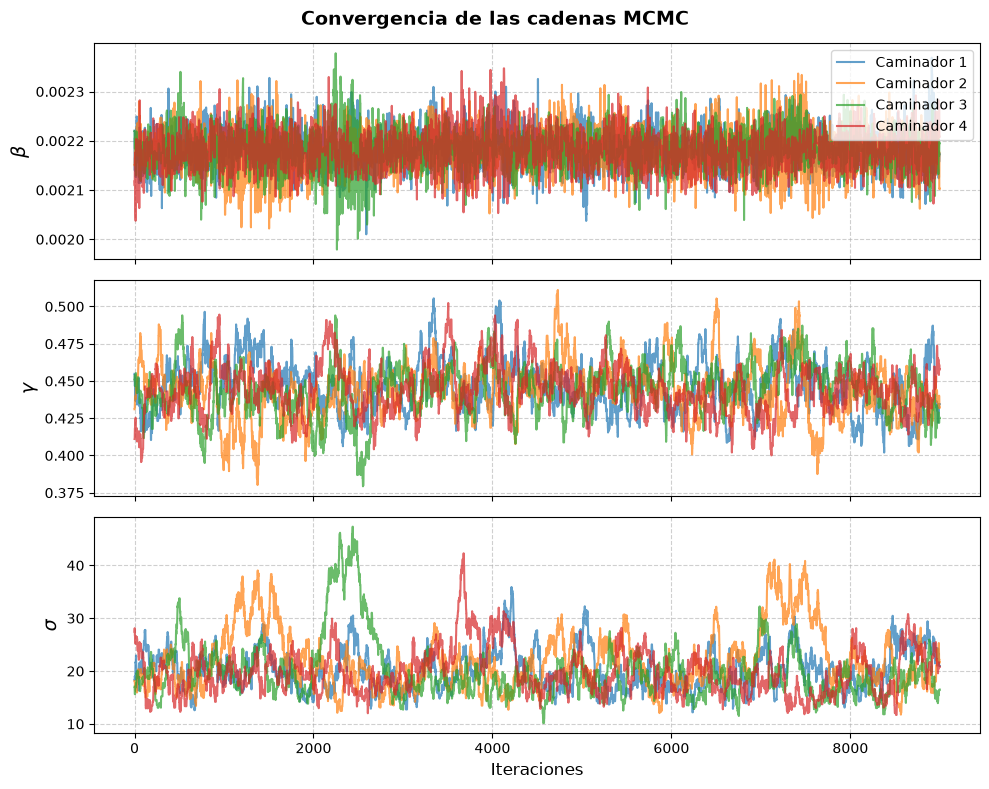

In [ ]:
# Nombres de los parámetros para las etiquetas
param_names = [r'$\beta$', r'$\gamma$', r'$\sigma$']
n_params = len(param_names)

fig, axes = plt.subplots(n_params, 1, figsize=(10, 8), sharex=True)

# Graficar la evolución de cada parámetro para cada caminador
for i in range(n_params):
    for j in range(n_chains):
        # walks[j][:, i] extrae todas las iteraciones del parámetro i para el caminador j
        axes[i].plot(chains[j][1000:, i], alpha=0.7, label=f'Caminador {j+1}' if i == 0 else "")

    axes[i].set_ylabel(param_names[i], fontsize=14)
    axes[i].grid(True, linestyle="--", alpha=0.6)

# Configuraciones finales de la gráfica
axes[0].legend(loc='upper right', frameon=True)
axes[-1].set_xlabel("Iteraciones", fontsize=12)
plt.suptitle("Convergencia de las cadenas", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [11]:
for i in range(0,4):
    print(np.mean(chains[i][1500:], axis = 0))

[2.18294050e-03 4.47565276e-01 2.01610494e+01]
[2.17949946e-03 4.43087510e-01 2.21401489e+01]
[2.18097506e-03 4.44658050e-01 2.00728497e+01]
[2.18152270e-03 4.44670894e-01 1.98943182e+01]
